In [ ]:
import pandas as pd
import numpy as np
import re
import nltk
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [ ]:
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


True

In [ ]:
import pandas as pd

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
# Check dataset information
print("Dataset Information:")
df.info()

# Check dataset shape
print("\nDataset Shape:", df.shape)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check first 5 records
df.head()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  704

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
print(df.shape)

(7043, 21)


In [ ]:
# Display dataset information
df.info()

# Display missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Display target column distribution
print("\nCustomer Churn Distribution:")
print(df['Churn'].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

print("TotalCharges converted successfully!")
print(df['TotalCharges'].dtype)

TotalCharges converted successfully!
float64


In [ ]:
print("Missing values before cleaning:")
print(df.isnull().sum().sum())

df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

print("\nMissing values after cleaning:")
print(df.isnull().sum().sum())

Missing values before cleaning:
11

Missing values after cleaning:
0


In [ ]:
df = df.drop('customerID', axis=1)

print("CustomerID column removed!")
print("Dataset Shape:", df.shape)

CustomerID column removed!
Dataset Shape: (7043, 20)


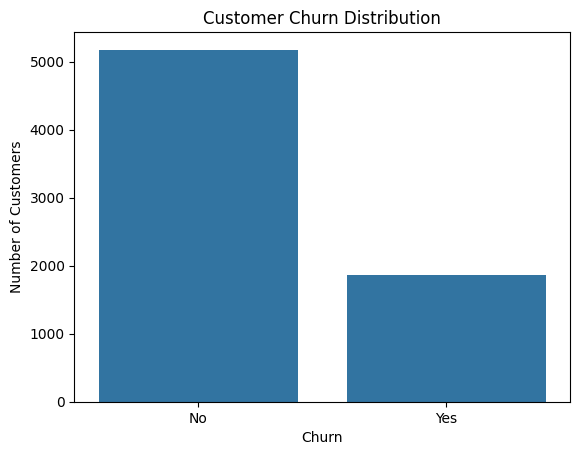

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(x='Churn', data=df)

plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')
plt.show()

In [ ]:
X = df.drop('Churn', axis=1)
y = df['Churn']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (7043, 19)
Target Shape: (7043,)


In [ ]:
y = y.map({'Yes': 1, 'No': 0})

print(y.value_counts())

Churn
0    5174
1    1869
Name: count, dtype: int64


In [ ]:
categorical_cols = X.select_dtypes(include=['object']).columns
numerical_cols = X.select_dtypes(exclude=['object']).columns

print("Categorical Columns:")
print(list(categorical_cols))

print("\nNumerical Columns:")
print(list(numerical_cols))

Categorical Columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical Columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [ ]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols),
        ('num', 'passthrough', numerical_cols)
    ]
)

X_encoded = preprocessor.fit_transform(X)

print("Encoding Completed!")
print("Encoded Feature Shape:", X_encoded.shape)

Encoding Completed!
Encoded Feature Shape: (7043, 45)


In [ ]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

In [ ]:
!pip install imbalanced-learn

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (5634, 45)
Testing Data: (1409, 45)


In [ ]:
print("Before SMOTE:")
print(y_train.value_counts())

Before SMOTE:
Churn
0    4139
1    1495
Name: count, dtype: int64


In [ ]:
smote = SMOTE(random_state=42)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train,
    y_train
)

print("After SMOTE:")
print(y_train_balanced.value_counts())

After SMOTE:
Churn
0    4139
1    4139
Name: count, dtype: int64


In [ ]:
!pip install xgboost

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

print("Model libraries imported successfully!")

Model libraries imported successfully!


In [ ]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    class_weight='balanced'
)

rf_model.fit(X_train_balanced, y_train_balanced)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [ ]:
xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    random_state=42,
    eval_metric='logloss'
)

xgb_model.fit(X_train_balanced, y_train_balanced)

print("XGBoost Model Trained Successfully!")

XGBoost Model Trained Successfully!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("Evaluation libraries imported successfully!")

Evaluation libraries imported successfully!


In [ ]:
rf_predictions = rf_model.predict(X_test)
rf_probabilities = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest Predictions Completed!")

Random Forest Predictions Completed!


In [ ]:
xgb_predictions = xgb_model.predict(X_test)
xgb_probabilities = xgb_model.predict_proba(X_test)[:, 1]

print("XGBoost Predictions Completed!")

XGBoost Predictions Completed!


In [ ]:
results = pd.DataFrame({
    'Model': ['Random Forest', 'XGBoost'],
    'Accuracy': [
        accuracy_score(y_test, rf_predictions),
        accuracy_score(y_test, xgb_predictions)
    ],
    'Precision': [
        precision_score(y_test, rf_predictions),
        precision_score(y_test, xgb_predictions)
    ],
    'Recall': [
        recall_score(y_test, rf_predictions),
        recall_score(y_test, xgb_predictions)
    ],
    'F1 Score': [
        f1_score(y_test, rf_predictions),
        f1_score(y_test, xgb_predictions)
    ],
    'ROC-AUC': [
        roc_auc_score(y_test, rf_probabilities),
        roc_auc_score(y_test, xgb_probabilities)
    ]
})

results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,0.774308,0.569652,0.612299,0.590206,0.834367
1,XGBoost,0.794890,0.621083,0.582888,0.601379,0.842447


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

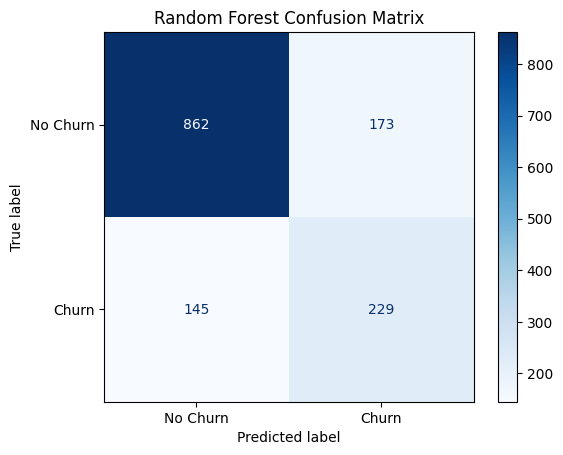

In [ ]:
rf_cm = confusion_matrix(y_test, rf_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=rf_cm,
    display_labels=['No Churn', 'Churn']
)

disp.plot(cmap='Blues')
plt.title('Random Forest Confusion Matrix')
plt.show()

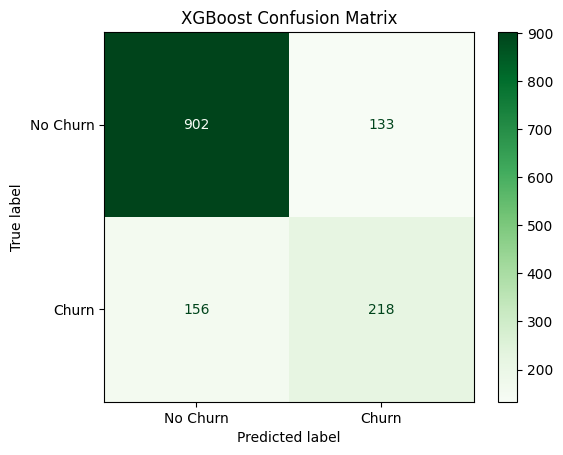

In [ ]:
xgb_cm = confusion_matrix(y_test, xgb_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=xgb_cm,
    display_labels=['No Churn', 'Churn']
)

disp.plot(cmap='Greens')
plt.title('XGBoost Confusion Matrix')
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print("RANDOM FOREST CLASSIFICATION REPORT")
print(classification_report(y_test, rf_predictions))

print("\nXGBOOST CLASSIFICATION REPORT")
print(classification_report(y_test, xgb_predictions))

RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.86      0.83      0.84      1035
           1       0.57      0.61      0.59       374

    accuracy                           0.77      1409
   macro avg       0.71      0.72      0.72      1409
weighted avg       0.78      0.77      0.78      1409


XGBOOST CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.85      0.87      0.86      1035
           1       0.62      0.58      0.60       374

    accuracy                           0.79      1409
   macro avg       0.74      0.73      0.73      1409
weighted avg       0.79      0.79      0.79      1409



In [ ]:
from sklearn.metrics import roc_curve, auc

print("ROC libraries imported successfully!")

ROC libraries imported successfully!


In [ ]:
rf_fpr, rf_tpr, rf_thresholds = roc_curve(
    y_test, rf_probabilities
)

rf_auc = auc(rf_fpr, rf_tpr)

print("Random Forest ROC-AUC:", rf_auc)

Random Forest ROC-AUC: 0.8343666847503165


In [ ]:
xgb_fpr, xgb_tpr, xgb_thresholds = roc_curve(
    y_test, xgb_probabilities
)

xgb_auc = auc(xgb_fpr, xgb_tpr)

print("XGBoost ROC-AUC:", xgb_auc)

XGBoost ROC-AUC: 0.8424474928311246


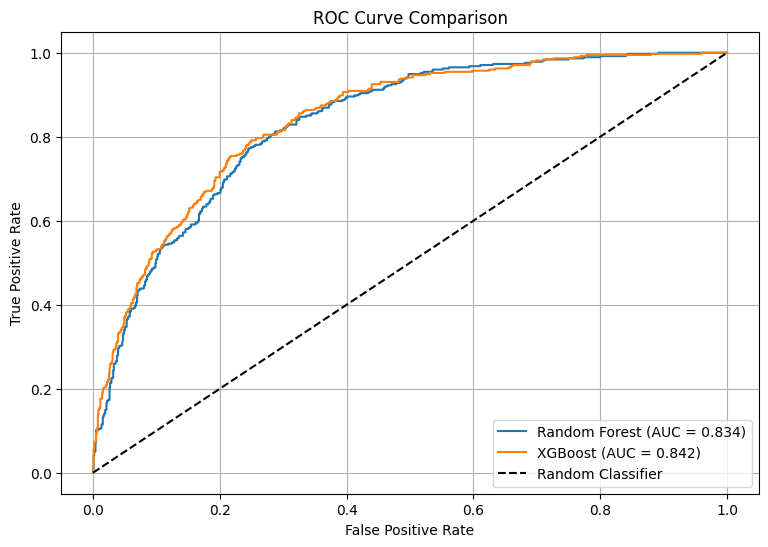

In [ ]:
plt.figure(figsize=(9, 6))

plt.plot(
    rf_fpr, rf_tpr,
    label=f'Random Forest (AUC = {rf_auc:.3f})'
)

plt.plot(
    xgb_fpr, xgb_tpr,
    label=f'XGBoost (AUC = {xgb_auc:.3f})'
)

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')

plt.legend()
plt.grid()
plt.show()

In [ ]:
feature_names = preprocessor.get_feature_names_out()

print("Total Features:", len(feature_names))
print("Feature names:")
print(feature_names)

Total Features: 45
Feature names:
['cat__gender_Female' 'cat__gender_Male' 'cat__Partner_No'
 'cat__Partner_Yes' 'cat__Dependents_No' 'cat__Dependents_Yes'
 'cat__PhoneService_No' 'cat__PhoneService_Yes' 'cat__MultipleLines_No'
 'cat__MultipleLines_No phone service' 'cat__MultipleLines_Yes'
 'cat__InternetService_DSL' 'cat__InternetService_Fiber optic'
 'cat__InternetService_No' 'cat__OnlineSecurity_No'
 'cat__OnlineSecurity_No internet service' 'cat__OnlineSecurity_Yes'
 'cat__OnlineBackup_No' 'cat__OnlineBackup_No internet service'
 'cat__OnlineBackup_Yes' 'cat__DeviceProtection_No'
 'cat__DeviceProtection_No internet service' 'cat__DeviceProtection_Yes'
 'cat__TechSupport_No' 'cat__TechSupport_No internet service'
 'cat__TechSupport_Yes' 'cat__StreamingTV_No'
 'cat__StreamingTV_No internet service' 'cat__StreamingTV_Yes'
 'cat__StreamingMovies_No' 'cat__StreamingMovies_No internet service'
 'cat__StreamingMovies_Yes' 'cat__Contract_Month-to-month'
 'cat__Contract_One year' 'cat__Con

In [ ]:
rf_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_model.feature_importances_
})

rf_importance = rf_importance.sort_values(
    by='Importance', ascending=False
)

print("Top 10 Random Forest Features:")
display(rf_importance.head(10))

Top 10 Random Forest Features:


,Feature,Importance
32,cat__Contract_Month-to-month,0.105001
14,cat__OnlineSecurity_No,0.093968
39,cat__PaymentMethod_Electronic check,0.089780
23,cat__TechSupport_No,0.081515
42,num__tenure,0.061109
44,num__TotalCharges,0.055352
34,cat__Contract_Two year,0.050628
17,cat__OnlineBackup_No,0.045935
12,cat__InternetService_Fiber optic,0.032701
43,num__MonthlyCharges,0.030510


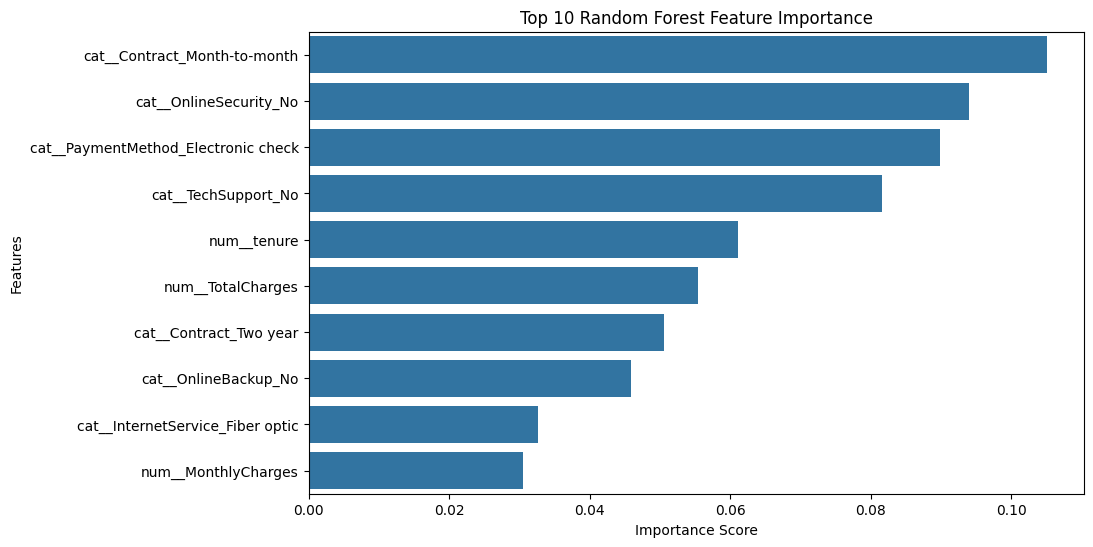

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=rf_importance.head(10),
    x='Importance',
    y='Feature'
)

plt.title('Top 10 Random Forest Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

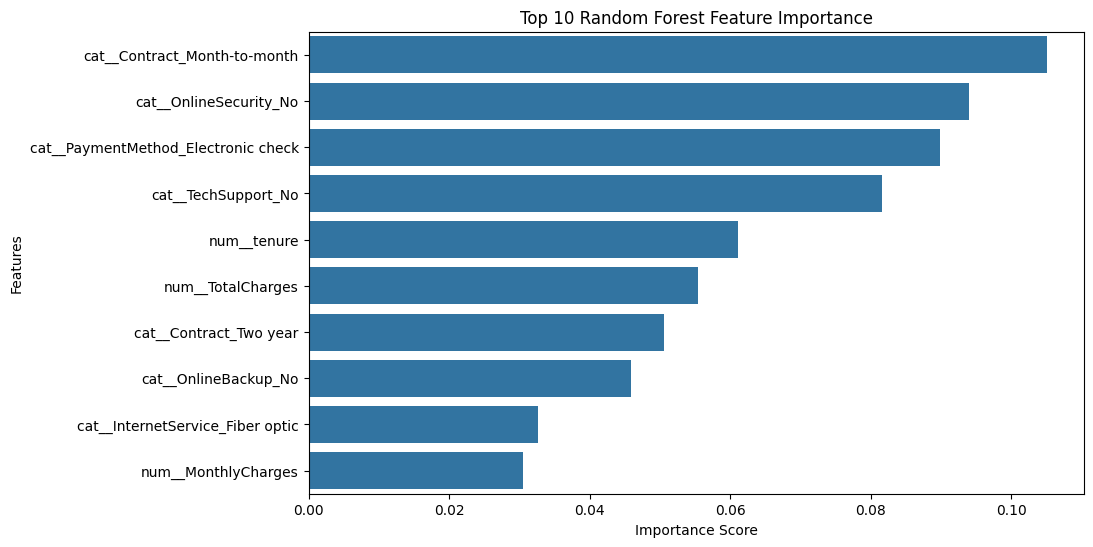

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=rf_importance.head(10),
    x='Importance',
    y='Feature'
)

plt.title('Top 10 Random Forest Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

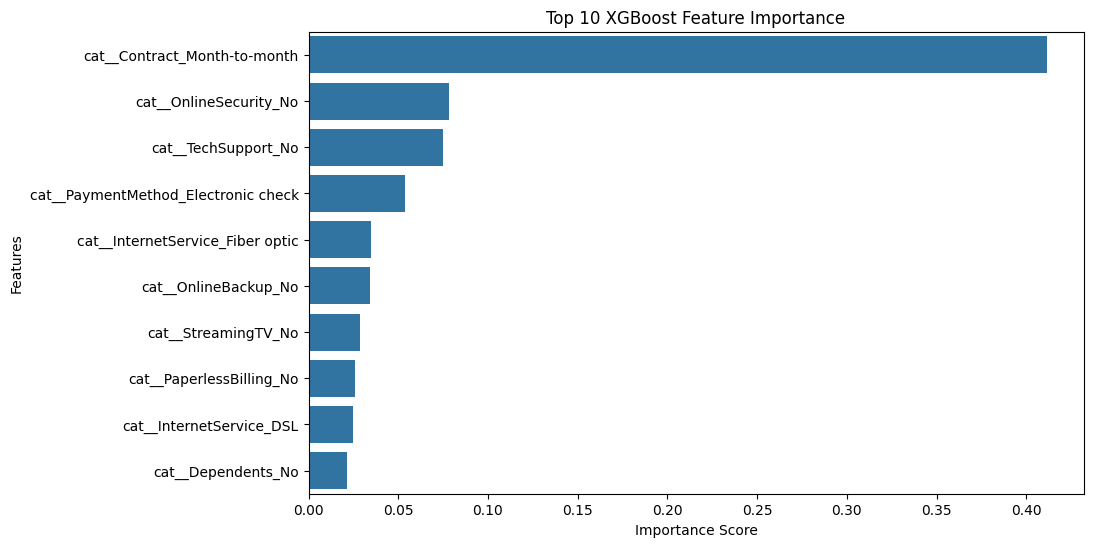

In [ ]:
xgb_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': xgb_model.feature_importances_
})

xgb_importance = xgb_importance.sort_values(
    by='Importance', ascending=False
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=xgb_importance.head(10),
    x='Importance',
    y='Feature'
)

plt.title('Top 10 XGBoost Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline

print("Cross-validation libraries imported successfully!")

Cross-validation libraries imported successfully!


In [ ]:
rf_pipeline = ImbPipeline(steps=[
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        random_state=42
    ))
])

print("Random Forest pipeline created!")

Random Forest pipeline created!


In [ ]:
xgb_pipeline = ImbPipeline(steps=[
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('classifier', XGBClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=5,
        random_state=42,
        eval_metric='logloss'
    ))
])

print("XGBoost pipeline created!")

XGBoost pipeline created!


In [ ]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf_cv_scores = cross_val_score(
    rf_pipeline, X, y,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1
)

xgb_cv_scores = cross_val_score(
    xgb_pipeline, X, y,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1
)

print("Random Forest CV Scores:", rf_cv_scores)
print("Random Forest Mean ROC-AUC:", rf_cv_scores.mean())

print("\nXGBoost CV Scores:", xgb_cv_scores)
print("XGBoost Mean ROC-AUC:", xgb_cv_scores.mean())

Random Forest CV Scores: [0.84827689 0.8388566  0.85078922 0.82362876 0.82981826]
Random Forest Mean ROC-AUC: 0.8382739454881412

XGBoost CV Scores: [0.8550828  0.83976207 0.84832339 0.82898421 0.83740781]
XGBoost Mean ROC-AUC: 0.8419120562048935


In [ ]:
comparison = pd.DataFrame({
    'Model': ['Random Forest', 'XGBoost'],
    'Test ROC-AUC': [rf_auc, xgb_auc],
    'CV Mean ROC-AUC': [
        rf_cv_scores.mean(),
        xgb_cv_scores.mean()
    ]
})

display(comparison)

,Model,Test ROC-AUC,CV Mean ROC-AUC
0,Random Forest,0.834367,0.838274
1,XGBoost,0.842447,0.841912


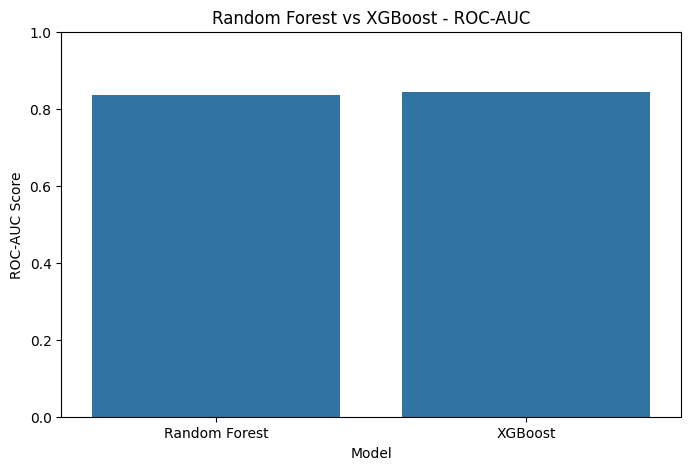

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=comparison,
    x='Model',
    y='Test ROC-AUC'
)

plt.title('Random Forest vs XGBoost - ROC-AUC')
plt.ylim(0, 1)
plt.ylabel('ROC-AUC Score')
plt.show()

In [ ]:
if xgb_auc > rf_auc:
    best_model = xgb_model
    best_model_name = "XGBoost"
    best_auc = xgb_auc
else:
    best_model = rf_model
    best_model_name = "Random Forest"
    best_auc = rf_auc

print("Best Model:", best_model_name)
print("Best Test ROC-AUC:", round(best_auc, 4))

Best Model: XGBoost
Best Test ROC-AUC: 0.8424


In [ ]:
print("PREDICTIVE CUSTOMER CHURN CLASSIFIER")
print("------------------------------------")

print("Dataset Records:", len(df))
print("Features Used:", X.shape[1])

print("\nRandom Forest ROC-AUC:", round(rf_auc, 4))
print("XGBoost ROC-AUC:", round(xgb_auc, 4))

print("\nRandom Forest CV Mean:", round(rf_cv_scores.mean(), 4))
print("XGBoost CV Mean:", round(xgb_cv_scores.mean(), 4))

print("\nBest Performing Model:", best_model_name)

PREDICTIVE CUSTOMER CHURN CLASSIFIER
------------------------------------
Dataset Records: 7043
Features Used: 19

Random Forest ROC-AUC: 0.8344
XGBoost ROC-AUC: 0.8424

Random Forest CV Mean: 0.8383
XGBoost CV Mean: 0.8419

Best Performing Model: XGBoost


In [ ]:
import joblib
import os

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
os.makedirs("models", exist_ok=True)

print("Models folder created successfully!")

Models folder created successfully!


In [ ]:
joblib.dump(rf_model, "models/random_forest_model.pkl")

print("Random Forest model saved!")

Random Forest model saved!


In [ ]:
joblib.dump(xgb_model, "models/xgboost_model.pkl")

print("XGBoost model saved!")

XGBoost model saved!


In [ ]:
os.makedirs("results", exist_ok=True)

print("Results folder created successfully!")

Results folder created successfully!


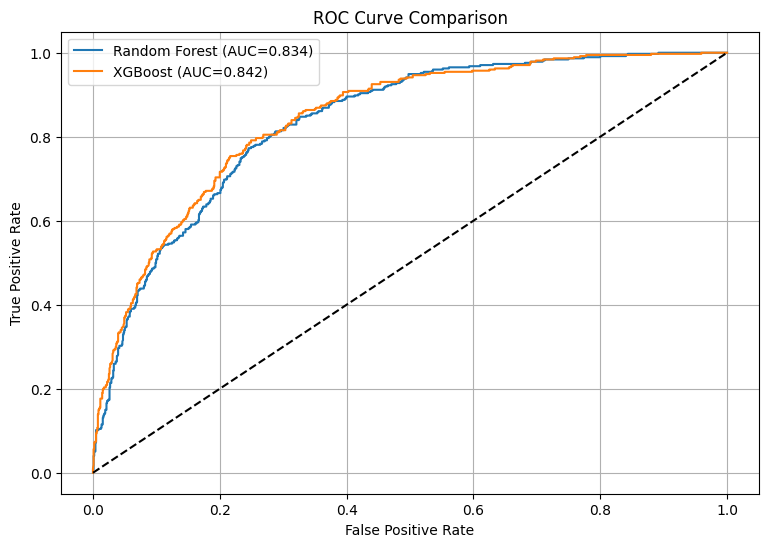

ROC Curve saved!


In [ ]:
plt.figure(figsize=(9, 6))

plt.plot(rf_fpr, rf_tpr, label=f'Random Forest (AUC={rf_auc:.3f})')
plt.plot(xgb_fpr, xgb_tpr, label=f'XGBoost (AUC={xgb_auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid()

plt.savefig("results/roc_curve_comparison.png", dpi=300, bbox_inches='tight')
plt.show()

print("ROC Curve saved!")

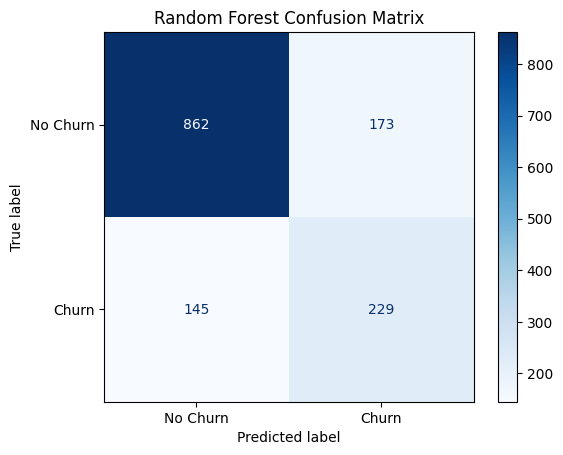

Random Forest confusion matrix saved!


In [ ]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=rf_cm,
    display_labels=['No Churn', 'Churn']
)

disp.plot(cmap='Blues')
plt.title("Random Forest Confusion Matrix")

plt.savefig("results/random_forest_confusion_matrix.png",
            dpi=300, bbox_inches='tight')
plt.show()

print("Random Forest confusion matrix saved!")

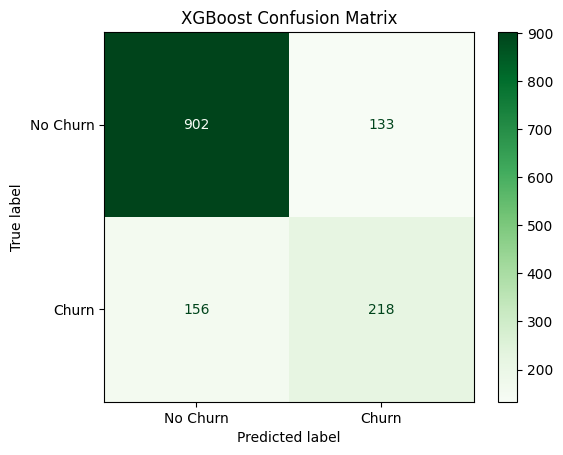

XGBoost confusion matrix saved!


In [ ]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=xgb_cm,
    display_labels=['No Churn', 'Churn']
)

disp.plot(cmap='Greens')
plt.title("XGBoost Confusion Matrix")

plt.savefig("results/xgboost_confusion_matrix.png",
            dpi=300, bbox_inches='tight')
plt.show()

print("XGBoost confusion matrix saved!")

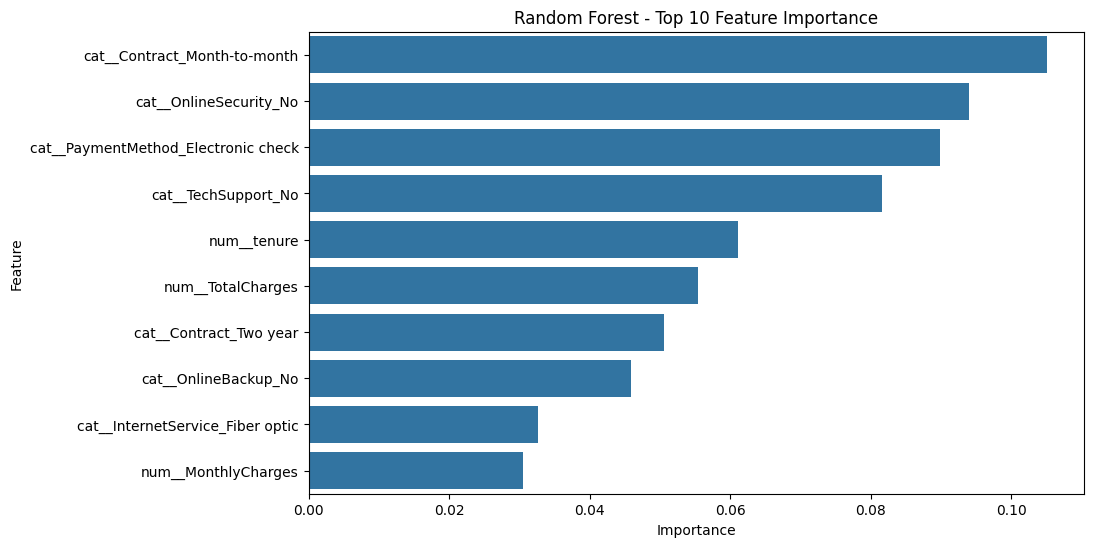

Random Forest feature importance saved!


In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=rf_importance.head(10),
    x='Importance',
    y='Feature'
)

plt.title('Random Forest - Top 10 Feature Importance')
plt.savefig('results/random_forest_feature_importance.png',
            dpi=300, bbox_inches='tight')
plt.show()

print("Random Forest feature importance saved!")

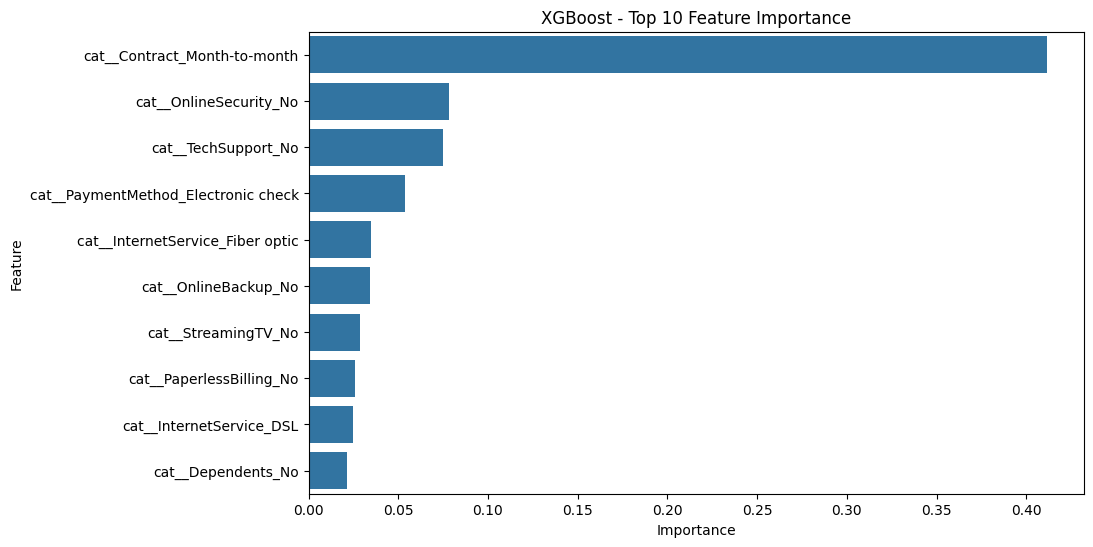

XGBoost feature importance saved!


In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=xgb_importance.head(10),
    x='Importance',
    y='Feature'
)

plt.title('XGBoost - Top 10 Feature Importance')
plt.savefig('results/xgboost_feature_importance.png',
            dpi=300, bbox_inches='tight')
plt.show()

print("XGBoost feature importance saved!")

<Figure size 800x500 with 0 Axes>

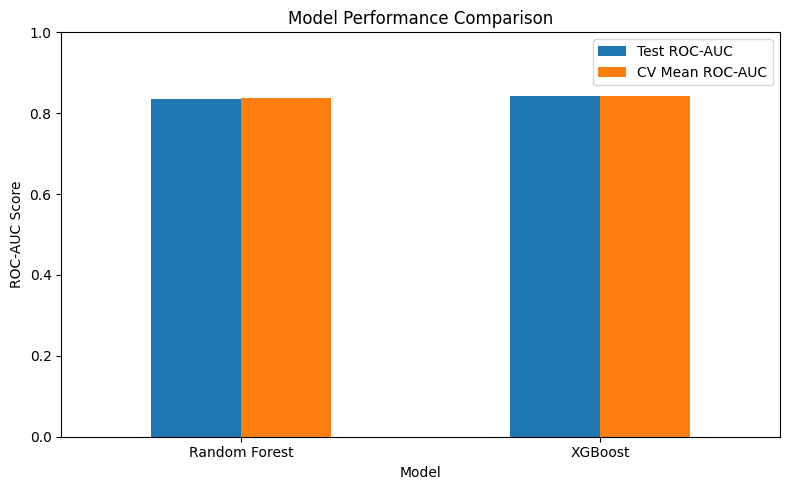

Model comparison chart saved!


In [ ]:
plt.figure(figsize=(8, 5))

comparison.set_index('Model').plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Model Performance Comparison')
plt.ylabel('ROC-AUC Score')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig('results/model_performance_comparison.png',
            dpi=300, bbox_inches='tight')
plt.show()

print("Model comparison chart saved!")

In [ ]:
comparison.to_csv(
    'results/model_performance_results.csv',
    index=False
)

print("Performance results saved successfully!")
print(comparison)

Performance results saved successfully!
           Model  Test ROC-AUC  CV Mean ROC-AUC
0  Random Forest      0.834367         0.838274
1        XGBoost      0.842447         0.841912


In [ ]:
import shutil

print("ZIP library ready!")

ZIP library ready!


In [ ]:
os.makedirs("Predictive-Customer-Churn", exist_ok=True)

print("Project folder created!")

Project folder created!


In [ ]:
shutil.copytree(
    "models",
    "Predictive-Customer-Churn/models",
    dirs_exist_ok=True
)

shutil.copytree(
    "results",
    "Predictive-Customer-Churn/results",
    dirs_exist_ok=True
)

print("Models and results copied successfully!")

Models and results copied successfully!


In [ ]:
shutil.make_archive(
    "Predictive-Customer-Churn",
    "zip",
    root_dir="Predictive-Customer-Churn"
)

print("ZIP file created successfully!")

ZIP file created successfully!


In [ ]:
from google.colab import files

files.download("Predictive-Customer-Churn.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
readme = """
# Predictive Customer Churn Classifier

## Project Overview
This project predicts customer churn using Machine Learning
algorithms: Random Forest and XGBoost.

## Dataset
IBM Telco Customer Churn Dataset

- Total Records: 7043
- Features: 20
- Target: Churn (Yes/No)

## Technologies Used
- Python
- Pandas
- NumPy
- Scikit-learn
- XGBoost
- Imbalanced-learn
- Matplotlib
- Seaborn

## Machine Learning Models
1. Random Forest Classifier
2. XGBoost Classifier

## Techniques Used
- Data Preprocessing
- OneHotEncoder
- SMOTE
- Stratified Cross-Validation
- ROC-AUC Evaluation

## Results
- ROC Curve Comparison
- Confusion Matrices
- Feature Importance Charts
- Model Performance Comparison

## Project Structure
- models/
- results/
- README.md
- Predictive_Customer_Churn.ipynb
"""

with open("README.md", "w") as file:
    file.write(readme)

print("README.md created successfully!")

README.md created successfully!


In [ ]:
with open("README.md", "r") as file:
    print(file.read())


# Predictive Customer Churn Classifier

## Project Overview
This project predicts customer churn using Machine Learning
algorithms: Random Forest and XGBoost.

## Dataset
IBM Telco Customer Churn Dataset

- Total Records: 7043
- Features: 20
- Target: Churn (Yes/No)

## Technologies Used
- Python
- Pandas
- NumPy
- Scikit-learn
- XGBoost
- Imbalanced-learn
- Matplotlib
- Seaborn

## Machine Learning Models
1. Random Forest Classifier
2. XGBoost Classifier

## Techniques Used
- Data Preprocessing
- OneHotEncoder
- SMOTE
- Stratified Cross-Validation
- ROC-AUC Evaluation

## Results
- ROC Curve Comparison
- Confusion Matrices
- Feature Importance Charts
- Model Performance Comparison

## Project Structure
- models/
- results/
- README.md
- Predictive_Customer_Churn.ipynb



In [ ]:
from google.colab import files

files.download("README.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>